# Подготовка кругов и исследовательский анализ F1

## tl;dr

Из 3 826 исходных кругов Catalunya 2023–2025 сохранено 3 362 (87.87%), исключено 464 (12.13%). Все причины сохранены отдельно. Составы шин варьируются во всех трёх гонках, а температура сильно различается между годами. Графики описывают выбранные обычные сухие круги; причинные эффекты шин или погоды они не устанавливают.

Проверяемая версия результата: [cleaning.json](../reports/cleaning.json), [eda.json](../reports/eda.json). При изменении входа пересчитайте этот краткий итог по таблицам ниже.

## Context & Methods

Задача — прогноз длительности обычного круга **до его начала**. Ноутбук читает PostgreSQL через SQL, не CSV и не JSON-выгрузки. Требуется предварительный `f1-pipeline prepare --verify-repeat`.

Источники: [OpenF1 / stints](https://openf1.org/docs/#stints), [laps](https://openf1.org/docs/#laps), [weather](https://openf1.org/docs/#weather), [race_control](https://openf1.org/docs/#race-control). Правила: [preparation.md](../docs/preparation.md), [features.md](../docs/features.md). SQL объединения: [005_prepare_candidates.sql](../sql/005_prepare_candidates.sql); SQL чтения: [006_training_read.sql](../sql/006_training_read.sql).

### Key Assumptions

- `tyre_age_before_lap = tyre_age_at_start + lap_number - lap_start`: только завершённые круги.
- Погода: последний timestamp до старта, давность ≤120 с. Timestamp источника не гарантирует нулевую задержку доставки API.
- Состав и возраст установленного комплекта считаются известными команде до круга; исторические stints не дают timestamp их объявления.
- Pit-in, текущие флаги и дождь во время круга — только ретроспективные причины отбора. Это условная оценка на чистых сухих кругах.
- Жёлтый мини-сектор исключает перекрывающиеся круги консервативно, без знания точного положения автомобиля.
- История берётся только из завершённых прошлых кругов того же пилота/сессии; она может включать предыдущий pit/SC круг. Пропуски не заполняются, масштабирование не обучается.

## Data

### 1. Подключение и разрешённые столбцы

Команды запуска из корня репозитория:
```bash
python -m pip install -e '.[dev,notebook]'
f1-pipeline prepare --verify-repeat
python scripts/check_notebook.py notebooks/02_preparation_eda.ipynb
```
Пароль читается из `.env` и нигде не печатается.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML, Markdown
from f1_pipeline.db import connect
from f1_pipeline.eda import load_analysis, plot_analysis
from f1_pipeline.prepare import FEATURE_COLUMNS

%matplotlib inline
import matplotlib.pyplot as plt
plt.ioff()

frame, evidence = load_analysis()

def show_table(rows, columns=None):
    table = pd.DataFrame(rows)
    if columns is not None:
        table = table[columns]
    labels = {"year":"Год", "n":"Круги", "drivers":"Пилоты", "compounds":"Составы",
        "raw":"Исходные", "accepted":"Приняты", "excluded":"Исключены",
        "history_missing":"История: NULL", "reason":"Причина", "laps":"Круги",
        "percent_of_raw":"% исходных", "lap_number":"Круг", "compound":"Состав",
        "stint_lap_start":"Начало stint", "tyre_age_at_stint_start":"Возраст в начале",
        "tyre_age_before_lap":"Возраст до круга", "field":"Поле", "missing":"NULL",
        "min_seconds":"Min, с", "max_seconds":"Max, с", "min_track_c":"Min трассы, °C",
        "max_track_c":"Max трассы, °C", "median_seconds":"Медиана, с", "std_seconds":"SD, с",
        "mean_track_c":"Трасса, °C", "std_track_c":"SD трассы, °C", "pearson_track_duration":"Pearson r"}
    table = table.rename(columns=labels)
    display(HTML(table.to_html(index=False, escape=True, float_format=lambda x: f"{x:.3f}")))

assert len(frame) == evidence["checks"]["rows"]
assert not frame.duplicated(["session_key", "driver_number", "lap_number"]).any()
print(f"SQL rows: {len(frame)}; features: {', '.join(FEATURE_COLUMNS)}")

SQL rows: 3362; features: compound, tyre_age_before_lap, air_temperature, track_temperature, driver_name, lap_number, previous_lap_duration


### 2. Покрытие и очистка по гонкам

Одна запись соответствует одному кругу. Число пилотов — участники конкретной гонки, а не уникальные люди за все годы.

In [2]:
show_table(evidence["cleaning"])
show_table(evidence["by_race"], ["year", "n", "drivers", "compounds", "history_missing"])
show_table([{ "Проверка": k, "Ошибок": evidence["checks"][k]} for k in ["future_timestamps", "missing_required", "audit_mismatch", "history_mismatch", "weather_not_latest"]])

Приняты,Исключены,Исходные,Год
1207,105,1312,2023
1166,144,1310,2024
989,215,1204,2025


Год,Круги,Пилоты,Составы,История: NULL
2023,1207,20,3,20
2024,1166,20,3,20
2025,989,19,3,19


Проверка,Ошибок
future_timestamps,0
missing_required,0
audit_mismatch,0
history_mismatch,0
weather_not_latest,0


### 3. Причины исключения

Причины пересекаются. Для каждого кода число делится на все исходные круги; суммы процентов не обязаны равняться общей доле исключений.

In [3]:
with connect() as conn:
    reasons = conn.execute("""
        SELECT reason, count(*) AS laps,
               round(100.0*count(*)/(SELECT count(*) FROM analytics.lap_observations),2) AS percent_of_raw
        FROM analytics.lap_observations a CROSS JOIN LATERAL unnest(a.exclusion_reasons) AS reason
        GROUP BY reason ORDER BY laps DESC,reason
    """).fetchall()
show_table(reasons)

Причина,Круги,% исходных
pit_in,139,3.63
pit_out,139,3.63
safety_car,113,2.95
yellow_flag,72,1.88
first_lap,59,1.54
rain,40,1.05
missing_target,5,0.13
invalid_temperature,3,0.08
missing_start,3,0.08
missing_weather,3,0.08


### 4. Пробег шин на реальных отрезках

Расселл, 2024: использованный SOFT начинается с возраста 3, новый MEDIUM — с 0. Текущий круг не добавляется к пробегу до его начала.

In [4]:
with connect() as conn:
    tyre_examples = conn.execute("""
        SELECT lap_number,compound,stint_lap_start,tyre_age_at_stint_start,tyre_age_before_lap
        FROM analytics.lap_observations
        WHERE session_key=9539 AND driver_number=63 AND lap_number IN (1,15,16,17,37,38)
        ORDER BY lap_number
    """).fetchall()
show_table(tyre_examples)
for row in tyre_examples:
    assert row["tyre_age_before_lap"] == row["tyre_age_at_stint_start"] + row["lap_number"] - row["stint_lap_start"]

Круг,Состав,Начало stint,Возраст в начале,Возраст до круга
1,SOFT,1,3,3
15,SOFT,1,3,17
16,MEDIUM,16,0,0
17,MEDIUM,16,0,1
37,HARD,37,0,0
38,HARD,37,0,1


### 5. Пропуски, диапазоны и временные следы

Пропуски прошлых времён оставлены для этапа обучения. Краткая таблица показывает диапазоны; погода/история отдельно проверены SQL по исходным ключам и timestamp.

In [5]:
features_and_target = frame[list(FEATURE_COLUMNS)+["lap_duration"]]
show_table([{"field":name, "missing":int(features_and_target[name].isna().sum())} for name in features_and_target])
show_table(evidence["by_race"], ["year", "min_seconds", "max_seconds", "min_track_c", "max_track_c"])
assert (frame.weather_at <= frame.lap_start_at).all()
history = frame[frame.previous_lap_end_at.notna()]
assert (history.previous_lap_end_at <= history.lap_start_at).all()
assert (history.previous_lap_number < history.lap_number).all()
print("Уникальность, временные границы и разделение истории проверены")

Поле,NULL
compound,0
tyre_age_before_lap,0
air_temperature,0
track_temperature,0
driver_name,0
lap_number,0
previous_lap_duration,59
lap_duration,0


Год,"Min, с","Max, с","Min трассы, °C","Max трассы, °C"
2023,76.330,83.489,26.800,33.400
2024,77.115,89.605,38.300,43.600
2025,75.743,90.665,46.500,49.900


Уникальность, временные границы и разделение истории проверены


## Results

Четыре разных типа графиков: гистограмма, линия, boxplot, scatter. Числовые данные всех графиков читаются из БД; одинаковые цвета и шкалы помогают сравнивать сессии. Код построения: `f1_pipeline.eda.plot_analysis`.

In [6]:
figures = plot_analysis(frame)

### 6. Распределение времени

Общие границы интервалов; плотность учитывает разное число кругов. Пунктир — медиана. Все сохранённые медленные круги включены.

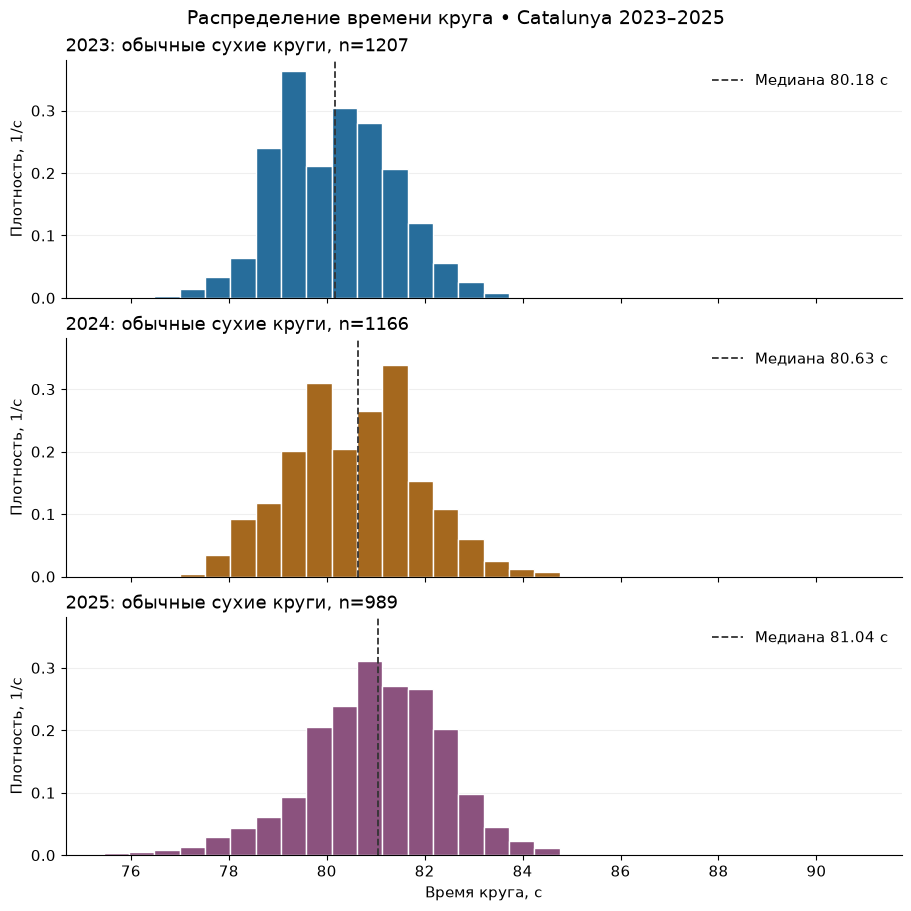

Год,Круги,"Медиана, с","SD, с"
2023,1207,80.178,1.183
2024,1166,80.631,1.333
2025,989,81.043,1.432


In [7]:
display(figures["01_distribution"])
show_table(evidence["by_race"], ["year", "n", "median_seconds", "std_seconds"])

Правый хвост остаётся после удаления формальных ограничений; это может быть трафик или отдельные инциденты. Удалять такие круги по будущей ошибке модели нельзя.

### 7. Динамика темпа по кругам

Один пилот — Max Verstappen, номер 1 — во всех гонках. Разрывы означают исключённые круги и не соединяются линиями.

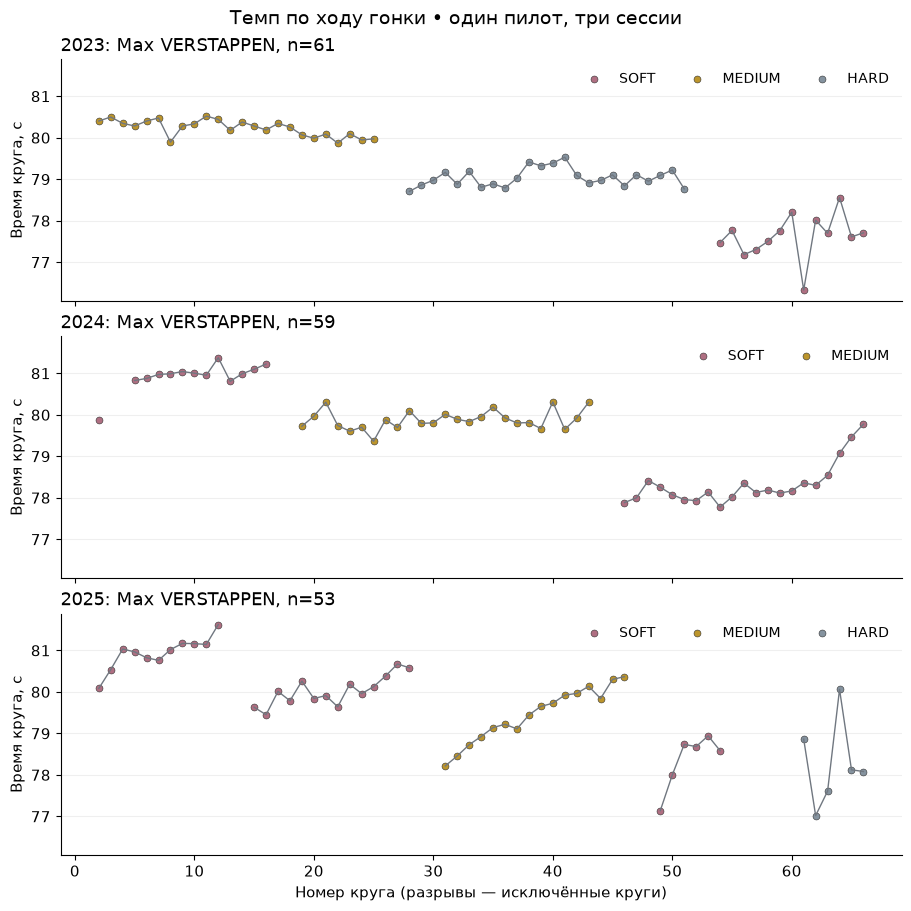

In [8]:
display(figures["02_lap_dynamics"])

Смена шин совпадает с изменениями темпа, но одновременно меняются топливо и трафик. По одной такой линии нельзя выделить чистую деградацию шин. Пропуск SC в 2025 году хорошо виден как большой разрыв.

### 8. Сравнение составов шин

Медиана, квартильный диапазон, усы 1.5 IQR и все точки за усами. Подписи n указывают покрытие.

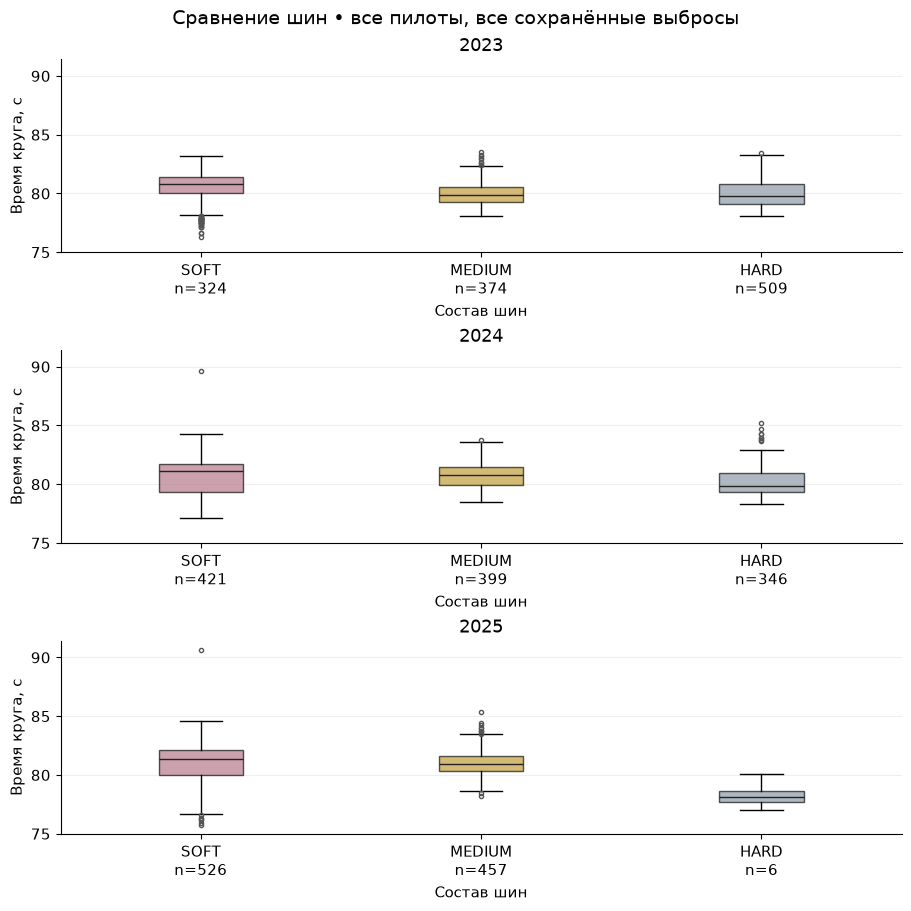

Год,Состав,Круги,Пилоты,"Медиана, с"
2023,HARD,509,18,79.774
2023,MEDIUM,374,15,79.867
2023,SOFT,324,19,80.785
2024,HARD,346,13,79.869
2024,MEDIUM,399,19,80.783
2024,SOFT,421,20,81.143
2025,HARD,6,1,78.102
2025,MEDIUM,457,18,80.959
2025,SOFT,526,19,81.358


In [9]:
display(figures["03_compounds"])
show_table(evidence["by_compound"], ["year", "compound", "n", "drivers", "median_seconds"])

Разные составы применялись на разных этапах гонки и разными пилотами. Разницу медиан нельзя интерпретировать как причинное преимущество SOFT/MEDIUM/HARD. Абсолютный состав C1..C5 может различаться по годам. HARD в 2025 году представлен только шестью кругами одного пилота после Safety Car; вывод о его скорости особенно ненадёжен.

### 9. Связь с температурой трассы

Точка — один круг. Панели разделены по гонкам; оси общие. Число точек не равно числу независимых погодных наблюдений.

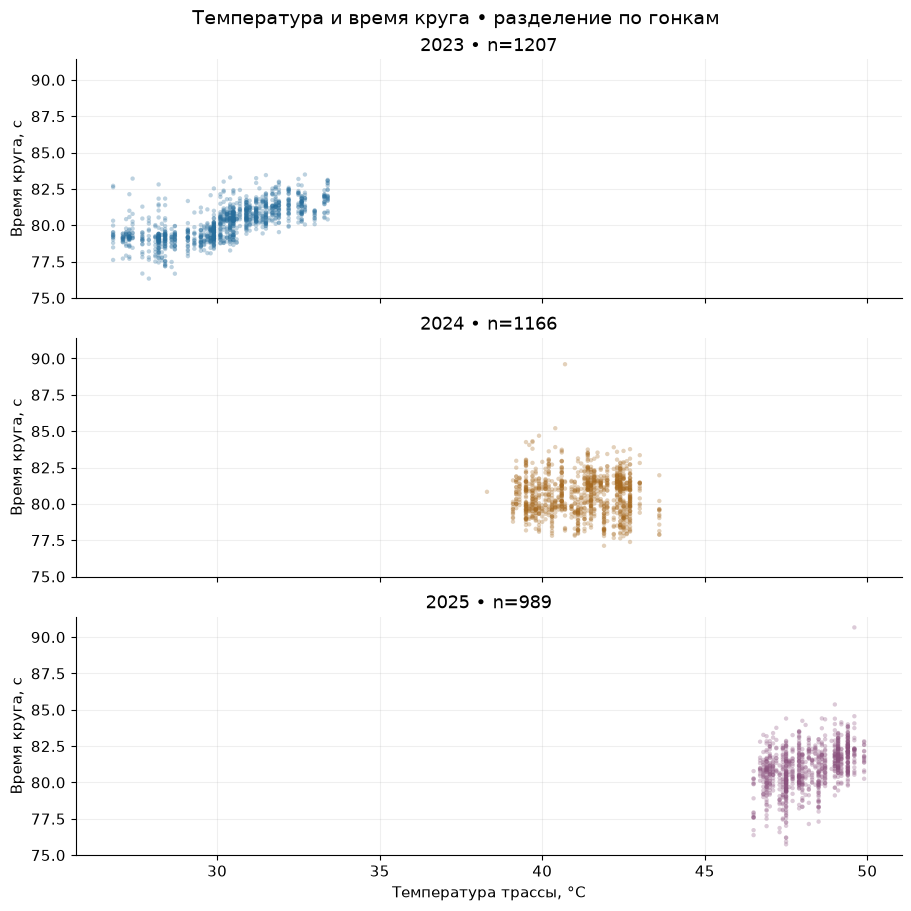

Год,"Трасса, °C","SD трассы, °C",Pearson r
2023,30.185,1.604,0.703
2024,41.188,1.141,-0.008
2025,48.164,0.919,0.437


Описательная корреляция температуры трассы и времени круга: **2023: r=0.703; 2024: r=-0.008; 2025: r=0.437**. Различия между годами подтверждают, что единую причинную зависимость по этим данным установить нельзя.

In [10]:
display(figures["04_temperature"])
show_table(evidence["by_race"], ["year", "mean_track_c", "std_track_c", "pearson_track_duration"])
values = "; ".join(f"{r['year']}: r={r['pearson_track_duration']:.3f}" for r in evidence["by_race"])
display(Markdown(f"Описательная корреляция температуры трассы и времени круга: **{values}**. Различия между годами подтверждают, что единую причинную зависимость по этим данным установить нельзя."))

## Takeaways

- Итоговая таблица готова к обучению собственной ООП-модели: обязательные признаки полны, предыдущие времена остаются nullable.
- Все причины исключения можно проверить в `analytics.lap_observations`; SC/VSC, pit-in/out и дождь не являются прогнозными входами.
- Только три гонки, погодные сценарии заметно различаются между годами. Трафик, топливо и изменения машин не наблюдаются в текущей модели; начало круга приблизительное.
- На следующем этапе использовать целые гонки и хронологию: 2023 train, 2024 validation, 2025 final test. 2025 уже показан для описательного анализа; его метрики нельзя использовать при подборе модели или порогов.
- Кодирование, масштабирование и заполнение истории обучать только на train. Для нового пилота нужна обработка неизвестной категории.
- Предыдущие времена доступны только при последовательном прогнозе перед каждым кругом; для прогноза всей гонки до старта такая история недоступна.

Артефакты: [отчёт очистки](../reports/cleaning.md), [EDA и картинки](../reports/eda.md), [проверка повторения](../reports/repeat_preparation.json).